# 03 — Exact Classical Reference vs. Ket QAOA and FALQON

**HYPAQ Ports · Reproducible integration comparison · Apache-2.0**

**Execution:** Ket circuits on CPU KBW, not quantum hardware. Default final
counts are reproducible classical draws through Ket's seeded snapshot sampler
from a KBW-computed state. Training and feedback use analytic simulator
expectations, not shot-estimated measurements. No classical simulator fallback
replaces Ket when an error occurs.

Install the pinned dependencies from the repository root before running:

```bash
python -m pip install -r requirements-quantum.txt
```

For Google Colab, clone the repository and install requirements as described in
`notebooks/quantum/README.md`. Run all cells in order. The quantum add-on must
already be merged into the repository.


## 1. Use a shared input and explicit configuration

Both quantum methods use the same cost scaling, penalty, initial uniform state and original operational validator. Their algorithm budgets differ; this is not a matched-resource performance study.

In [1]:
from pathlib import Path
import sys
import json
from IPython.display import display, HTML
from html import escape

ROOT = next((p for p in (Path.cwd(), *Path.cwd().parents)
             if (p / "src/hypaq_ports/quantum/ket_backend.py").is_file()
             and (p / "data/synthetic/berth_tiny_v1.json").is_file()), None)
if ROOT is None:
    raise RuntimeError("Merge the quantum add-on into hypaq-ports first. See notebooks/quantum/README.md for Colab setup.")
sys.path.insert(0, str(ROOT / "src"))
from hypaq_ports.reference import load_json, solve_berth_exact, build_berth_qubo
from hypaq_ports.quantum import run_qaoa, run_falqon
from hypaq_ports.quantum.ket_backend import environment

instance = load_json(ROOT / "data/synthetic/berth_tiny_v1.json")
config = load_json(ROOT / "results/quantum/berth_experiment.json")
print(json.dumps(environment(), indent=2))
print("Instance:", instance["instance_id"])

def show_rows(rows):
    keys = list(rows[0])
    def cell(value):
        if value is None:
            return "—"
        if isinstance(value, float):
            return f"{value:.6g}"
        return escape(str(value))
    header = "".join(f"<th>{escape(k)}</th>" for k in keys)
    body = "".join("<tr>" + "".join(f"<td>{cell(r.get(k))}</td>" for k in keys) + "</tr>" for r in rows)
    display(HTML(f"<table><thead><tr>{header}</tr></thead><tbody>{body}</tbody></table>"))


{
  "python": "3.12.14",
  "platform": "Linux-6.18.57-x86_64-with-glibc2.39",
  "ket_lang": "0.10.4.2",
  "ket_components": [
    "Ket v0.10.4.2",
    "libket v0.7.1 [rustc 1.97.1 (8bab26f4f 2026-07-14) x86_64-unknown-linux-gnu]",
    "kbw v0.5.1 [GPU, CUDA] [rustc 1.97.1 (8bab26f4f 2026-07-14) x86_64-unknown-linux-gnu]"
  ],
  "numpy": "2.3.5",
  "scipy": "1.17.0"
}
Instance: berth_tiny_v1


In [2]:
print(json.dumps(config, indent=2))
import importlib.util
spec = importlib.util.spec_from_file_location("ports_quantum_comparison", ROOT / "results/quantum/run_berth_comparison.py")
comparison_module = importlib.util.module_from_spec(spec)
spec.loader.exec_module(comparison_module)


{
  "experiment_id": "berth_qaoa_falqon_ket_v1",
  "instance_path": "data/synthetic/berth_tiny_v1.json",
  "classical_base_commit": "d094fc6c65504636a47b8bb5d2fcaa4ac1207944",
  "common": {
    "seed": 42,
    "shots": 4096,
    "sampling": "state_snapshot",
    "simulator": "sparse"
  },
  "qaoa": {
    "p": 2,
    "max_evaluations": 80,
    "restarts": 2
  },
  "falqon": {
    "layers": 64,
    "delta_t": 0.05
  },
  "comparison_note": "Illustrative configuration, not matched resources or a multi-instance performance benchmark"
}


## 2. Run all methods

The classical reference proves its tiny-instance optimum through exhaustive enumeration. QAOA and FALQON retain heuristic status even if a sampled solution matches that optimum. CP-SAT has not been added.

In [3]:
report = comparison_module.generate_comparison()
show_rows(report["summary"])
for key in ("qaoa", "falqon"):
    r = report[key]
    assert abs(r["metrics"]["expected_full_qubo_energy"] - r["final_full_energy_from_observable"]) < 0.003
    assert sum(r["counts"].values()) == config["common"]["shots"]
print("Limitations:")
for item in report["limitations"]:
    print("-", item)


Limitations:
- No quantum hardware
- No CP-SAT adapter in this package
- Exact state-vector expectations, not shot-estimated training
- Final seeded sampling uses a dumped KBW state, not native KBW or QPU measurements
- Tiny zero-wait optimum; no relative approximation ratio
- Resource budgets differ; no speedup or algorithm-ranking claim
- FALQON first-order discretization may exhibit energy increases


method,best_feasible_waiting_slots,exact_feasible_probability,sampled_feasible_rate,exact_optimal_probability,full_qubo_energy,cost_expectation_queries,feedback_expectation_queries,logical_gate_count,logical_depth,seconds
Exact enumeration,0,—,—,—,—,—,—,—,—,9.0154e-05
QAOA,0,0.23665,0.231689,0.172132,2.3848,161,0,136,50,2.75999
FALQON,0,0.408951,0.4104,0.338561,2.13178,65,64,4096,1103,1.91141


## 3. Compare distribution quality

Use the simulator's full distribution to distinguish feasible from optimal
probability. Empirical sample frequencies are separate columns in the table.
Both algorithms can find a zero-wait sample while assigning substantial
probability to infeasible states. The exact classical solver returns a schedule,
not a quantum state distribution, so its probability columns are undefined.

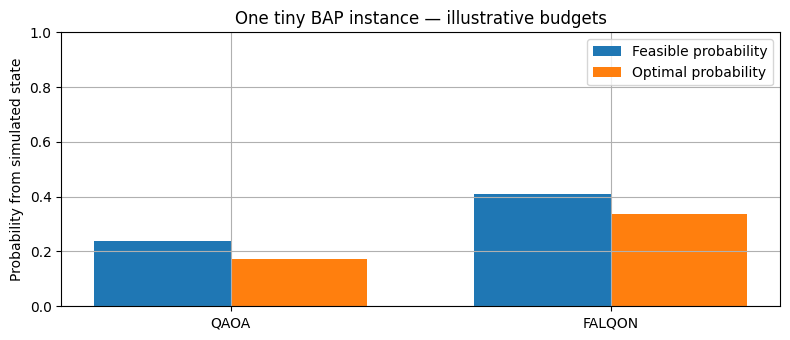

In [4]:
%matplotlib inline
import matplotlib.pyplot as plt
plt.rcParams.update({"figure.figsize": (8, 3.5), "axes.grid": True})
import numpy as np
labels = ["QAOA", "FALQON"]
results = [report["qaoa"], report["falqon"]]
x = np.arange(2)
plt.bar(x-0.18, [r["metrics"]["exact_feasible_probability"] for r in results], width=0.36, label="Feasible probability")
plt.bar(x+0.18, [r["metrics"]["exact_optimal_probability"] for r in results], width=0.36, label="Optimal probability")
plt.xticks(x, labels); plt.ylim(0, 1); plt.ylabel("Probability from simulated state")
plt.title("One tiny BAP instance — illustrative budgets")
plt.legend(); plt.tight_layout(); plt.show()


## 4. Export and extend

The committed `results/quantum/berth_comparison_reference.json` and CSV were
produced by the standalone runner. To replace them with your own run:

```python
comparison_module.save_comparison(report)
```

Do not infer general superiority from this chart. The methods have different
layer, circuit-preparation, expectation-query and gate costs. Final-shot counts
exclude training measurements because training uses exact simulated expectations.
Since the operational optimum is zero, relative approximation ratios dividing by
the optimum are undefined. Use absolute gaps and conditional feasible costs.

Next extensions: an OR-Tools CP-SAT reference, a nontrivial instance suite,
multiple seeds, shot-estimated objectives/feedback and matched-resource protocols.
Consult `docs/quantum/README.md` before extending claims.